# 03. Primera prueba de modelado: CNN para HMS.

Esta primera línea base usa **todas las filas de desarrollo**: entrena con cuatro folds y valida con el fold 1 completo. El holdout de pacientes reservado no se toca. El fold 0 ya se consultó en el piloto, por lo que este experimento usa un fold distinto; sus resultados son diagnósticos y no se usarán para ajustar repetidamente el modelo.

Se conserva la distribución natural (sin balancear ni sobremuestrear las clases), se comparan Macro F1 y accuracy contra la clase mayoritaria, y se grafica la pérdida en entrenamiento/validación. Las tres épocas quedan fijadas antes de ejecutar; no se usa early stopping para evitar decidir mirando la misma validación.

**En VS Code:** selecciona el kernel `Python (repo_machine_learning .venv)` en la esquina superior derecha y luego usa `Run All`. Si no aparece, reinicia VS Code después de crear el entorno virtual y ejecutar `python -m ipykernel install --user --name repo-machine-learning --display-name "Python (repo_machine_learning .venv)"`.

La transferencia de aprendizaje con una red preentrenada será una comparación posterior: requiere `torchvision` y acceso a los pesos; no se supone que una red de imágenes naturales sea mejor para espectrogramas EEG.

Preparando caché de 84,131 espectrogramas/ventanas (64x64) en disco...


Parquets procesados: 1,000/8,740


Parquets procesados: 2,000/8,740


Parquets procesados: 3,000/8,740


Parquets procesados: 4,000/8,740


Parquets procesados: 5,000/8,740


... (5 outputs left out)

Época 1/3 - pérdida train: 1.4947; pérdida validación: 1.5787; Macro F1 validación: 0.3162


Época 2/3 - pérdida train: 1.3654; pérdida validación: 1.4775; Macro F1 validación: 0.4212


Época 3/3 - pérdida train: 1.3220; pérdida validación: 1.5697; Macro F1 validación: 0.3836


Resultados de validación:
{
  "fold_id": 1,
  "architecture": "SpectrogramCNN",
  "sampling_strategy": "full_development",
  "random_state": 42,
  "baseline_reference": "majority class from all training folds before sampling",
  "epochs": 3,
  "image_size": 64,
  "train_samples": 67305,
  "validation_samples": 16826,
  "train_class_counts": {
    "Seizure": 13413,
    "LPD": 9538,
    "GPD": 10614,
    "LRDA": 10306,
    "GRDA": 11590,
    "Other": 11844
  },
  "validation_class_counts": {
    "Seizure": 3353,
    "LPD": 2385,
    "GPD": 2653,
    "LRDA": 2576,
    "GRDA": 2897,
    "Other": 2962
  },
  "training_history": [
    {
      "epoch": 1,
      "train_loss": 1.4946672093291737,
      "validation_loss": 1.578749087057201,
      "validation_accuracy": 0.33406632592416496,
      "validation_macro_f1": 0.31624392475570223
    },
    {
      "epoch": 2,
      "train_loss": 1.3654098837188426,
      "validation_loss": 1.4774924466092196,
      "validation_accuracy": 0.4172114584571

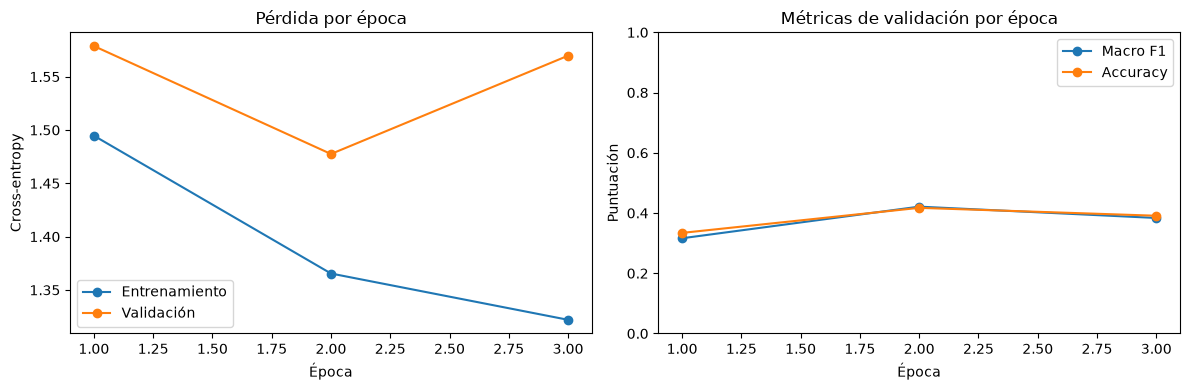

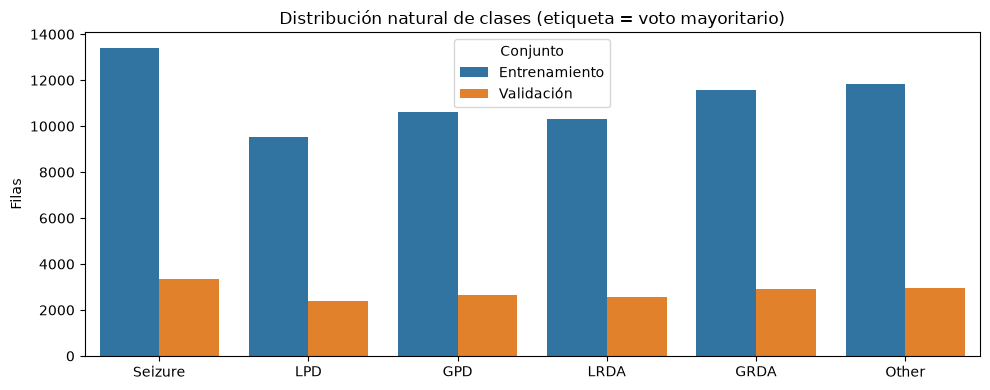

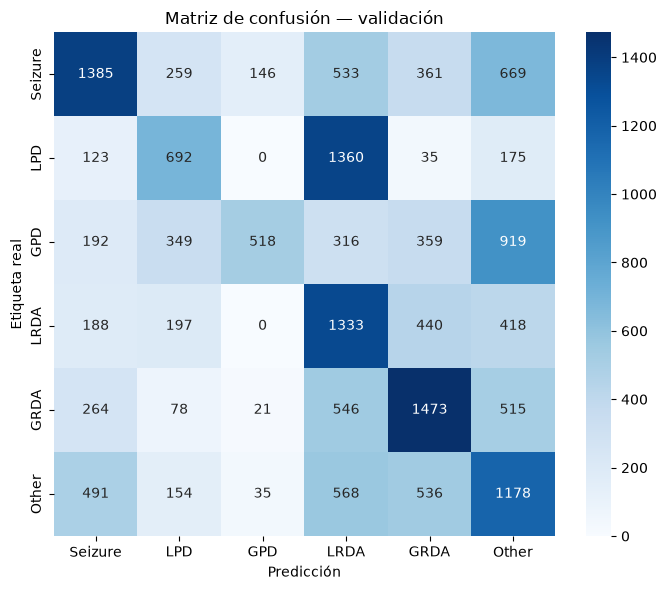

Matriz de confusión guardada en results\hms_cnn_confusion_matrix.csv
Modelo guardado en models\hms_cnn_baseline.pt


In [1]:
from pathlib import Path
import sys
import importlib.util

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src" / "hms_cnn.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto con src/hms_cnn.py.")
sys.path.insert(0, str(PROJECT_ROOT))
if importlib.util.find_spec("torch") is None:
    raise ModuleNotFoundError(
        f"El kernel actual ({sys.executable}) no tiene PyTorch. "
        "Abre repo_machine_learning como carpeta en VS Code y selecciona "
        "el kernel 'Python (repo_machine_learning .venv)'."
    )

from src.hms_cnn import run_experiment

metrics = run_experiment(
    project_root=PROJECT_ROOT,
    fold_id=1,
    max_train_samples=None,
    max_validation_samples=None,
    epochs=3,
    batch_size=64,
    image_size=64,
    random_state=42,
)